# 05 — Final test (locked period, scored once)

**Question.** How do the final model and the two vendor baselines score on the locked test period, which no
earlier notebook or run has loaded?

**Protocol (fixed before this notebook was executed).**

- Models: `007_hl365` (final best of the optimization loop, notebook 04), `002_vendor_raw` (raw vendor DA +
  empirical error quantiles) and `003_vendor_capacity` (step-1 capacity-corrected vendor DA + the same error
  quantiles). Configs are read unchanged from `experiments/configs/`.
- Each model is refit once on delivery days 2022-01-01 → 2026-04-30 (same model factory, features, 365-day
  recency weights and 90-day CQR as `windfc.run`) and predicts delivery days 2026-05-01 → 2026-10-28
  (`windfc.final.score_test`). Features for each test day use only data available at its issue time (D−1 10:00 UTC).
- Scored hours: the runner's common evaluation mask (valid actual and valid base features, vendor DA and last
  actual), identical for the three models; metrics from the frozen `windfc.evaluate` (commit `1b685ed`).
- Diebold–Mariano (frozen, HLN-corrected, h = 1, on delivery-day mean pinball loss): 007 vs 002 (total gain) and
  007 vs 003; 003 vs 002 as a supplementary check of step 1. Negative statistic = first model better.
- Also reported: CRPS by month (007 vs 002), P10–P90 coverage and bias by month, and reliability (share of actuals
  below each quantile).
- This notebook is executed once. Nothing here writes to `experiments/log.csv`. The interpretation cells at the
  end were written after that single execution, from its outputs.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml

from windfc import QUANTILES
from windfc.cutoff import delivery_day
from windfc.evaluate import QCOLS, TEST_PERIOD, diebold_mariano
from windfc.final import score_test
from windfc.run import REPO_ROOT as ROOT, read_log

DATA = None  # None = data/dk1_hourly.parquet
LOG = ROOT / "experiments" / "log.csv"
CONFIGS = ROOT / "experiments" / "configs"
FIG_DIR = ROOT / "docs" / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 160)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "lines.linewidth": 1.6, "legend.frameon": False,
})
C = {"blue": "#2a78d6", "orange": "#eb6834", "aqua": "#1baf7a", "ink": "#0b0b0b", "grey": "#8a8984"}

log = read_log(LOG).set_index("run_id")  # read only
log_before = LOG.read_bytes()
RUNS = ["002_vendor_raw", "003_vendor_capacity", "007_hl365"]
print("test period (delivery days):", TEST_PERIOD)

test period (delivery days): ('2026-05-01', '2026-10-28')


## 1. Fit once, score once

In [2]:
res = {rid: score_test(yaml.safe_load((CONFIGS / f"{rid}.yaml").read_text()), data_path=DATA)
       for rid in RUNS}
assert LOG.read_bytes() == log_before  # the log was not written
idx = res["007_hl365"]["predictions"].index
assert all(r["predictions"].index.equals(idx) for r in res.values())  # same scored hours for all three
for rid, r in res.items():
    dd = delivery_day(r["predictions"].index)
    print(f"{rid}: trained on {r['n_train']} hours; scored {r['n_hours']} hours "
          f"({dd.min().date()} .. {dd.max().date()}), dropped by mask {r['n_dropped']}")

002_vendor_raw: trained on 37559 hours; scored 4294 hours (2026-05-01 .. 2026-10-28), dropped by mask 51
003_vendor_capacity: trained on 37559 hours; scored 4294 hours (2026-05-01 .. 2026-10-28), dropped by mask 51
007_hl365: trained on 37502 hours; scored 4294 hours (2026-05-01 .. 2026-10-28), dropped by mask 51


In [3]:
metrics = ["crps", "mae_p50", "coverage_80", "bias", "crps_norm", "n_hours"]
tab = pd.DataFrame({rid: {k: r["scores"][k] for k in metrics} for rid, r in res.items()}).T
ref = tab.loc["002_vendor_raw"]
tab["CRPS vs 002 %"] = 100 * (tab.crps / ref.crps - 1)
tab["MAE vs 002 %"] = 100 * (tab.mae_p50 / ref.mae_p50 - 1)
val = log.loc[RUNS, ["crps_mean", "mae_p50_mean", "coverage_mean"]]
tab["validation CRPS"] = val.crps_mean
tab["validation CRPS vs 002 %"] = 100 * (val.crps_mean / val.loc["002_vendor_raw", "crps_mean"] - 1)
tab["n_hours"] = tab["n_hours"].astype(int)
tab.index.name = "test period"
tab.round(3)

,crps,mae_p50,coverage_80,bias,crps_norm,n_hours,CRPS vs 002 %,MAE vs 002 %,validation CRPS,validation CRPS vs 002 %
test period,,,,,,,,,,
002_vendor_raw,121.914,312.352,0.708,-171.796,0.069,4294,0.000,0.000,119.223,0.000
003_vendor_capacity,116.435,294.801,0.737,108.707,0.066,4294,-4.494,-5.619,120.736,1.269
007_hl365,128.506,344.094,0.762,-163.978,0.073,4294,5.407,10.163,106.940,-10.303


Units: CRPS (mean pinball loss over the 9 quantiles), P50 MAE and bias (mean P50 − actual) in MWh per hour;
`crps_norm` = CRPS / mean actual. Validation columns are the logged 4-fold means from `experiments/log.csv`.

In [4]:
# Point forecasts only (no error model), on the same scored hours, as in notebook 02 section 5:
# raw vendor DA total vs step-1 corrected DA total.
from windfc.capacity import apply_capacity_correction, capacity_ratio
from windfc.run import default_paths

raw = pd.read_parquet(DATA or default_paths()[0]).sort_index()
raw = raw[np.asarray(delivery_day(raw.index) <= pd.Timestamp(TEST_PERIOD[1]))]
test_days = pd.date_range(*TEST_PERIOD, freq="D")
adj = apply_capacity_correction(raw, capacity_ratio(raw, test_days)).reindex(idx)
pt = pd.DataFrame({
    "bias (MWh)": [(adj.da_total - adj.actual_total).mean(), (adj.da_total_adj - adj.actual_total).mean()],
    "MAE (MWh)": [(adj.da_total - adj.actual_total).abs().mean(), (adj.da_total_adj - adj.actual_total).abs().mean()],
}, index=["vendor DA raw", "vendor DA step-1 corrected"])
pt["MAE vs raw %"] = 100 * (pt["MAE (MWh)"] / pt["MAE (MWh)"].iloc[0] - 1)
pt.round(2)

,bias (MWh),MAE (MWh),MAE vs raw %
vendor DA raw,-459.76,537.17,0.00
vendor DA step-1 corrected,1.51,316.31,-41.12


## 2. Diebold–Mariano tests

In [5]:
loss = {rid: r["pinball"] for rid, r in res.items()}
pairs = [("007_hl365", "002_vendor_raw"), ("007_hl365", "003_vendor_capacity"),
         ("003_vendor_capacity", "002_vendor_raw")]
rows = []
for a, b in pairs:
    stat, p = diebold_mariano(loss[a], loss[b], h=1)
    rows.append(dict(model=a, vs=b, crps_a=loss[a].mean(), crps_b=loss[b].mean(),
                     d_crps_pct=100 * (loss[a].mean() / loss[b].mean() - 1),
                     n_days=delivery_day(loss[a].index).nunique(), dm_stat=stat, p_value=p))
dm = pd.DataFrame(rows).set_index(["model", "vs"])
dm.round(4)

crps_a   crps_b  d_crps_pct  n_days  dm_stat  p_value
model               vs                                                                         
007_hl365           002_vendor_raw       128.506  121.914       5.407     179    1.930    0.055
                    003_vendor_capacity  128.506  116.435      10.367     179    2.386    0.018
003_vendor_capacity 002_vendor_raw       116.435  121.914      -4.494     179   -1.186    0.237

## 3. By month

In [6]:
month = delivery_day(idx).to_period("M")
by_m = pd.DataFrame({
    "CRPS 002": loss["002_vendor_raw"].groupby(month).mean(),
    "CRPS 003": loss["003_vendor_capacity"].groupby(month).mean(),
    "CRPS 007": loss["007_hl365"].groupby(month).mean(),
})
by_m["007 vs 002 %"] = 100 * (by_m["CRPS 007"] / by_m["CRPS 002"] - 1)
for rid, short in [("002_vendor_raw", "002"), ("007_hl365", "007")]:
    p = res[rid]["predictions"]
    by_m[f"coverage {short}"] = ((p.q10 <= p.actual_total) & (p.actual_total <= p.q90)).groupby(month).mean()
    by_m[f"bias {short}"] = (p.q50 - p.actual_total).groupby(month).mean()
by_m["mean actual"] = res["007_hl365"]["predictions"].actual_total.groupby(month).mean()
by_m["hours"] = loss["007_hl365"].groupby(month).size()
by_m.index.name = "delivery month"
by_m.round(3)

,CRPS 002,CRPS 003,CRPS 007,007 vs 002 %,coverage 002,bias 002,coverage 007,bias 007,mean actual,hours
delivery month,,,,,,,,,,
2026-05,94.644,89.848,97.233,2.735,0.760,-42.163,0.784,-50.119,1230.957,693
2026-06,114.215,102.520,111.785,-2.128,0.728,-159.979,0.767,-141.492,1269.114,720
2026-07,115.204,130.085,132.999,15.446,0.716,-115.639,0.782,-198.450,1769.454,744
2026-08,114.900,117.089,141.695,23.320,0.727,-184.926,0.781,-188.917,1765.654,744
2026-09,149.493,135.926,161.469,8.011,0.646,-241.063,0.722,-264.068,2218.257,720
2026-10,143.898,122.036,123.787,-13.975,0.667,-291.385,0.737,-132.519,2371.932,673


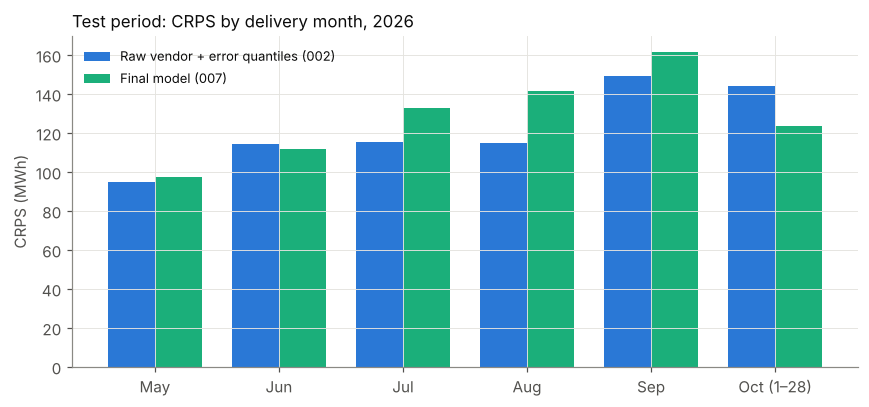

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
x = np.arange(len(by_m))
w = 0.38
ax.bar(x - w / 2, by_m["CRPS 002"], w, color=C["blue"], label="Raw vendor + error quantiles (002)")
ax.bar(x + w / 2, by_m["CRPS 007"], w, color=C["aqua"], label="Final model (007)")
ax.set_xticks(x)
ax.set_xticklabels([f"{p.strftime('%b')}" + (" (1–28)" if p.month == 10 else "") for p in by_m.index])
ax.set_ylabel("CRPS (MWh)")
ax.set_title("Test period: CRPS by delivery month, 2026", loc="left", fontsize=11)
ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
plt.show()

## 4. Reliability

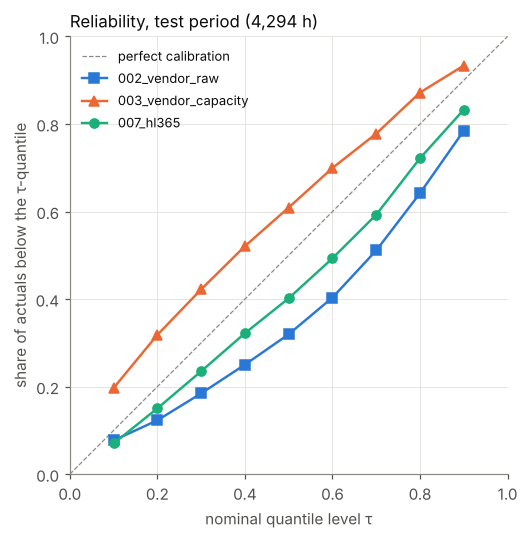

,002_vendor_raw,003_vendor_capacity,007_hl365
nominal τ,,,
0.1,0.077,0.197,0.070
0.2,0.123,0.318,0.150
0.3,0.185,0.422,0.235
0.4,0.250,0.521,0.322
0.5,0.320,0.609,0.402
0.6,0.404,0.700,0.493
0.7,0.511,0.778,0.593
0.8,0.642,0.872,0.722
0.9,0.785,0.934,0.833


In [8]:
rel = pd.DataFrame({rid: [(r["predictions"].actual_total <= r["predictions"][q]).mean() for q in QCOLS]
                    for rid, r in res.items()}, index=pd.Index(QUANTILES, name="nominal τ"))
fig, ax = plt.subplots(figsize=(5.2, 5))
ax.plot([0, 1], [0, 1], color=C["grey"], lw=0.8, ls="--", label="perfect calibration")
for (rid, colour), marker in zip({"002_vendor_raw": C["blue"], "003_vendor_capacity": C["orange"],
                                   "007_hl365": C["aqua"]}.items(), ["s", "^", "o"]):
    ax.plot(rel.index, rel[rid], color=colour, marker=marker, ms=6, label=rid)
ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.set_aspect("equal")
ax.set_xlabel("nominal quantile level τ")
ax.set_ylabel("share of actuals below the τ-quantile")
ax.set_title(f"Reliability, test period ({len(idx):,} h)", loc="left", fontsize=11)
ax.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
plt.show()
rel.round(3)

In [9]:
# Coverage of the final model by forecast-level quintile (constant-width CQR check, as in notebook 04)
p = res["007_hl365"]["predictions"].copy()
p["level_quintile"] = pd.qcut(p.q50, 5, labels=[f"Q{i}" for i in range(1, 6)])
p["inside"] = (p.actual_total >= p.q10) & (p.actual_total <= p.q90)
p.groupby("level_quintile", observed=True).agg(
    coverage=("inside", "mean"), mean_p50=("q50", "mean"),
    mean_residual=("q50", lambda s: (s - p.loc[s.index, "actual_total"]).mean()),
).round(3)

,coverage,mean_p50,mean_residual
level_quintile,,,
Q1,0.867,341.607,-2.907
Q2,0.792,930.989,16.573
Q3,0.761,1484.812,-194.579
Q4,0.765,2074.180,-261.872
Q5,0.627,3186.752,-377.140


## 5. Interpretation

*Written after the single execution of this notebook, from the outputs above. Executed once with
`jupyter nbconvert --execute --inplace`; no cell errored and nothing was re-run.*

**The final model does not beat the vendor on the test period.** `007_hl365` scores CRPS 128.5 MWh against
121.9 for the raw vendor baseline (**+5.4%, worse**) and 116.4 for the capacity-corrected vendor (**+10.4%, worse**).
Its P50 MAE is 10.2% worse than the raw vendor (344.1 vs 312.4 MWh). Diebold–Mariano: 007 vs 002 stat +1.93,
p = 0.055 (worse, not significant at 5%); 007 vs 003 stat +2.39, p = 0.018 (significantly worse). On validation the
same model was 10.3% *better* than 002 on CRPS; out of sample that gain did not shrink, it reversed.

**What held up, and what got worse.**

- **Step 1 (capacity correction) is the best of the three on test**, the opposite of validation. The `003` baseline is
  4.5% better than `002` on CRPS (DM p = 0.24, not significant) and 5.6% better on P50 MAE. As a point forecast,
  step 1 removes nearly all of the raw DA bias (−460 → +2 MWh) and cuts DA MAE by 41% (537 → 316 MWh). Its
  probabilistic version over-forecasts instead (P50 bias +109 MWh; 61% of actuals fall below its P50), consistent
  with notebook 02's untested hypothesis 1: the 90-day error offsets, learned in Feb–Apr 2026 when the corrected
  forecast was too low, push it up again in a period where it is roughly unbiased.
- **Coverage.** The final model's P10–P90 coverage is 0.762, just inside the 0.76–0.84 band; both vendor baselines
  fall below it (0.708 and 0.737). But its quantiles are centred too low: 40% of actuals fall below its P50, 16.7% above its P90 and 7.0% below its P10.
- **Bias.** The final model's P50 under-forecasts by 164 MWh on average, close to the raw vendor's −172 MWh,
  even though its main inputs are the step-1-corrected vendor forecasts, which are nearly unbiased on these hours.
- **By month.** The final model beats the raw vendor in June (−2.1%) and October (−14.0%) and loses in May (+2.7%),
  July (+15.4%), August (+23.3%) and September (+8.0%).
- **By forecast level.** The miss is concentrated in high-output hours: in the top quintile of the model's P50,
  coverage is 0.63 and the mean residual is −377 MWh; in the bottom quintile coverage is 0.87.

**Likely cause (hypothesis, not tested in this notebook).** The test period contains the largest offshore capacity
change of the data set (spec §5 kept it on purpose). Step 1 scales the vendor offshore forecast linearly, so it can
follow output above the historical range. A tree model does not extrapolate beyond the range it was trained
on: its splits on the corrected vendor features stop at the training maximum, so at the highest output levels it
therefore stays too low. The validation folds (May 2025 – Apr 2026) contain no comparable capacity step, so
nothing in the optimization loop could have detected this. The same pattern — the model doing worst where the
fleet differs most from training — fits the top-quintile residual above.

**Consequences.**

- On this test period, the honest ranking is: capacity-corrected vendor (003) ≥ raw vendor (002) > final model
  (007), with only the 007-vs-003 difference significant at 5%.
- The optimization loop selected well on its validation design (4 folds, one year) but that design did not
  represent a capacity step-up, so its −10.3% is not evidence of out-of-sample skill.
- The test period is now used. Any fix (for example a model of the residual of the step-1 forecast, or a model
  of capacity factor instead of MWh) needs a new validation design and a new untouched test window; it cannot be
  selected on these results.

## 6. Post-hoc diagnostic (added after the single test look — explanatory only, no model changed or re-scored)

Added after §5 was written, to check its extrapolation hypothesis. It uses the per-hour losses that `score_test`
already returned above; nothing is refit or re-predicted. The only new computation is the corrected vendor
features (`build_features`, same leakage-checked code), to find each one's maximum over the training period
(delivery days 2022-01-01 → 2026-04-30). A test hour is *out of range* if `da_off_adj` or `da_total_adj` is above
its training maximum.

In [10]:
from windfc.features import build_features

full = pd.read_parquet(DATA or default_paths()[0]).sort_index()
full = full[np.asarray(delivery_day(full.index) <= pd.Timestamp(TEST_PERIOD[1]))]
F, _ = build_features(full, pd.date_range("2022-01-01", TEST_PERIOD[1], freq="D"), ["da_off_adj", "da_total_adj"])
train = np.asarray(delivery_day(F.index) < pd.Timestamp(TEST_PERIOD[0]))
tmax = F[train].max()
Ft = F.reindex(idx)  # scored test hours
over = Ft.gt(tmax)
print(pd.DataFrame({"training max (MWh)": tmax, "test max (MWh)": Ft.max(),
                    "share of scored test hours above training max": over.mean()}).round(3).to_string())
out = over.any(axis=1)
split = pd.DataFrame({rid: [loss[rid][~out].mean(), loss[rid][out].mean(), loss[rid].mean()]
                      for rid in RUNS}, index=["in range", "out of range", "all"])
split["hours"] = [int((~out).sum()), int(out.sum()), len(out)]
split["007 vs 002 %"] = 100 * (split["007_hl365"] / split["002_vendor_raw"] - 1)
split["007 vs 003 %"] = 100 * (split["007_hl365"] / split["003_vendor_capacity"] - 1)
split.index.name = "CRPS (MWh)"
split.round(3)

              training max (MWh)  test max (MWh)  share of scored test hours above training max
da_off_adj              1510.108        2039.353                                          0.195
da_total_adj            4431.634        4629.702                                          0.006


,002_vendor_raw,003_vendor_capacity,007_hl365,hours,007 vs 002 %,007 vs 003 %
CRPS (MWh),,,,,,
in range,111.181,106.271,110.841,3456,-0.306,4.301
out of range,166.177,158.356,201.360,838,21.171,27.157
all,121.914,116.435,128.506,4294,5.407,10.367


**Reading (post-hoc).** 838 of the 4,294 scored test hours (19.5%) have a corrected offshore forecast above anything
in training (test max 2,039 vs training max 1,510 MWh). The corrected total leaves its training range in only 0.6% of
hours. On the out-of-range hours the final model's CRPS is 201.4 MWh: 21.2% worse than the raw vendor (166.2) and
27.2% worse than the capacity-corrected vendor (158.4). On the in-range hours it is level with the raw vendor
(110.8 vs 111.2, −0.3%) but still 4.3% worse than the capacity-corrected vendor (106.3). So extrapolation beyond the
training range accounts for most of the test-period loss against the raw vendor, but not for the loss against
step 1. This supports the extrapolation hypothesis of §5 but does not prove it: the split is descriptive, the
out-of-range hours are also the high-output hours, and no alternative model was fitted.

*Execution note.* The per-hour losses exist only while the notebook runs, so adding this section meant re-executing
the whole notebook once. All earlier cells (sources, text, table and image outputs) were compared with the committed
single-execution version and are byte-identical; the test numbers above did not change.